# ANN Baseline: Predicting the Heat Transfer Coefficient of Nanofluids
A feed-forward Artificial Neural Network (2 hidden layers) is trained to predict the Heat Transfer Coefficient (W/m²K) of a nanofluid from its composition, flow conditions and thermophysical properties.
Two optimizers, **Adam** and **RMSProp**, are compared on the same network and the same data split.

## Importing Libraries

In [1]:
import pandas as pa
import numpy as np
import matplotlib.pyplot as mplt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
import random
import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)

In [2]:
np.random.seed(50)
tf.random.set_seed(50)
random.seed(50)

In [3]:
# Reading the dataset
data=pa.read_excel("../data/nanofluid_dataset.xlsx")
data

,Nanoparticle_Type,Base_Fluid,Volume_Fraction (%),Temperature (Â°C),Flow_Velocity (m/s),Thermal_Conductivity (W/mK),Specific_Heat_Capacity (J/kgK),Density (kg/mÂ³),Viscosity (PaÂ·s),Heat_Transfer_Coefficient (W/mÂ²K)
0,CuO,Propylene Glycol,2.80,85.8,1.907,0.645,3356,1255,0.00901,2234.978690
1,SiO2,Water,2.77,71.6,0.681,1.622,3366,1402,0.00650,2118.965000
2,Al2O3,Propylene Glycol,2.56,90.0,1.526,1.809,1398,1973,0.00989,3321.034199
3,SiO2,Propylene Glycol,1.64,78.3,0.166,1.907,2408,1994,0.00546,1222.944448
4,CuO,Oil,2.11,61.0,2.316,0.600,2370,1701,0.00328,4796.976529
...,...,...,...,...,...,...,...,...,...,...
10288,SiO2,Oil,3.00,88.2,2.434,1.816,2872,1001,0.00168,6343.370655
10289,CuO,Ethylene Glycol,0.86,83.1,0.765,0.794,1535,1391,0.00414,1813.314501
10290,SiO2,Propylene Glycol,3.72,29.8,2.705,1.564,2380,1848,0.00193,7693.288592
10291,Al2O3,Oil,4.51,50.6,1.303,0.698,4217,1491,0.00190,2082.559663


In [4]:
#The column names in the excel file have an extra 'Â' character (encoding issue), for example W/mÂ²K and Â°C
#Removing it so that the units are displayed correctly
data.columns=[col.replace('Â','') for col in data.columns]
data.columns

Index(['Nanoparticle_Type', 'Base_Fluid', 'Volume_Fraction (%)',
       'Temperature (°C)', 'Flow_Velocity (m/s)',
       'Thermal_Conductivity (W/mK)', 'Specific_Heat_Capacity (J/kgK)',
       'Density (kg/m³)', 'Viscosity (Pa·s)',
       'Heat_Transfer_Coefficient (W/m²K)'],
      dtype='str')

In [5]:
target='Heat_Transfer_Coefficient (W/m²K)'

A=data.drop(columns=[target])            #Inputs
B=data[target]                           #Output

In [6]:
#Displaying shapes of both input and output
print("Original Data shape:", data.shape)
print("Input features(A) shape:", A.shape)
print("Output target(B) shape:", B.shape)

Original Data shape: (10293, 10)
Input features(A) shape: (10293, 9)
Output target(B) shape: (10293,)


In [7]:
#One-Hot Encoding both the Nanoparticle_Type and Base_Fluid as they are categorical variables
cat_cols=['Nanoparticle_Type','Base_Fluid']
A=pa.get_dummies(A,columns=cat_cols,dtype=float)

In [8]:
A

,Volume_Fraction (%),Temperature (°C),Flow_Velocity (m/s),Thermal_Conductivity (W/mK),Specific_Heat_Capacity (J/kgK),Density (kg/m³),Viscosity (Pa·s),Nanoparticle_Type_Al2O3,Nanoparticle_Type_CuO,Nanoparticle_Type_SiO2,Nanoparticle_Type_TiO2,Nanoparticle_Type_ZnO,Base_Fluid_Ethylene Glycol,Base_Fluid_Oil,Base_Fluid_Propylene Glycol,Base_Fluid_Water
0,2.80,85.8,1.907,0.645,3356,1255,0.00901,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,2.77,71.6,0.681,1.622,3366,1402,0.00650,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2.56,90.0,1.526,1.809,1398,1973,0.00989,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.64,78.3,0.166,1.907,2408,1994,0.00546,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,2.11,61.0,2.316,0.600,2370,1701,0.00328,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10288,3.00,88.2,2.434,1.816,2872,1001,0.00168,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
10289,0.86,83.1,0.765,0.794,1535,1391,0.00414,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
10290,3.72,29.8,2.705,1.564,2380,1848,0.00193,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
10291,4.51,50.6,1.303,0.698,4217,1491,0.00190,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [9]:
#Here we split the data into train,validation and test in 70:15:15
#The split is done BEFORE normalization so that the test data is not seen by the scaler

#First we split the data as per given ratio (70% and 30%) for the Temporary use
A_train,A_temp,B_train,B_temp=train_test_split(A,B,test_size=0.30,random_state=7)

#Now,split the temporary(30%) into two equal ratios i.e, 15% for Validation and 15% for Testing Set
A_val,A_test,B_val,B_test=train_test_split(A_temp,B_temp,test_size=0.50,random_state=7)

In [10]:
print("Original Data Size:",A.shape)
print("Training Set Size:",A_train.shape)
print("Validation Set Size:",A_val.shape)
print("Testing Set Size:",A_test.shape)

Original Data Size: (10293, 16)
Training Set Size: (7205, 16)
Validation Set Size: (1544, 16)
Testing Set Size: (1544, 16)


In [11]:
#Numerical input features which are to be rescaled between 0 and 1 (selected by name, not by position)
num_cols=['Volume_Fraction (%)','Temperature (°C)','Flow_Velocity (m/s)','Thermal_Conductivity (W/mK)',
          'Specific_Heat_Capacity (J/kgK)','Density (kg/m³)','Viscosity (Pa·s)']

#Fitting the scaler only on the training data and using the same scaler for validation and test data
scaler=MinMaxScaler()
A_train[num_cols]=scaler.fit_transform(A_train[num_cols])
A_val[num_cols]=scaler.transform(A_val[num_cols])
A_test[num_cols]=scaler.transform(A_test[num_cols])

In [12]:
A_train

,Volume_Fraction (%),Temperature (°C),Flow_Velocity (m/s),Thermal_Conductivity (W/mK),Specific_Heat_Capacity (J/kgK),Density (kg/m³),Viscosity (Pa·s),Nanoparticle_Type_Al2O3,Nanoparticle_Type_CuO,Nanoparticle_Type_SiO2,Nanoparticle_Type_TiO2,Nanoparticle_Type_ZnO,Base_Fluid_Ethylene Glycol,Base_Fluid_Oil,Base_Fluid_Propylene Glycol,Base_Fluid_Water
9762,0.261224,0.720994,0.791820,0.735823,0.912573,0.898789,0.412797,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4024,0.246939,0.429558,0.243379,0.553942,0.318014,0.880623,0.021672,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
9939,0.961224,0.107735,0.276232,0.545643,0.233492,0.544118,0.356037,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
8853,0.940816,0.102210,0.322494,0.121024,0.133386,0.474048,0.736842,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2289,0.222449,0.864641,0.857526,0.941217,0.290280,0.403979,0.697626,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
919,0.120408,0.502762,0.456252,0.758645,0.378500,0.123702,0.479876,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4307,0.132653,0.632597,0.119678,0.869295,0.918119,0.589100,0.769866,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5699,0.044898,0.198895,0.939993,0.852697,0.377179,0.509516,0.726522,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
537,0.524490,0.850829,0.065370,0.437068,0.418384,0.236159,0.433437,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [13]:
#Scaling the output between 0 and 1 (fitted only on the training output)
scaler_B=MinMaxScaler()
B_train_s=scaler_B.fit_transform(B_train.values.reshape(-1,1))
B_val_s=scaler_B.transform(B_val.values.reshape(-1,1))

## Creating a ANN Model

In [14]:
#Setting the seed again so that both the optimizers start from the same initial weights
tf.keras.utils.set_random_seed(50)

#Building a ANN Model
model=Sequential([
    Input(shape=(A_train.shape[1],)),
    Dense(12,activation='relu'),
    Dense(8,activation='relu'),
    Dense(1,activation='linear')
])

#Compiling model with adam
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [15]:
#verbose=0 to keep the notebook short, the loss curves are plotted in the comparison section
history= model.fit(A_train,B_train_s,
                    validation_data=(A_val,B_val_s),
                    epochs=100,
                    batch_size=32,
                    verbose=0)

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           204 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 953 (3.73 KB)

 Trainable params: 317 (1.24 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 636 (2.49 KB)

In [17]:
#Calculating MSE for the training data
#The predictions are converted back to the original units (W/m²K) before calculating the error
B_train_p=scaler_B.inverse_transform(model.predict(A_train,verbose=0))
mse_adam=mean_squared_error(B_train,B_train_p)
print("Training MSE:",mse_adam)

Training MSE: 103409.38855699051


## R² value for Training Data

In [18]:
#Calculating R^2 score on the training data

r2_train_adam = r2_score(B_train,B_train_p)
print("R² on training data:", r2_train_adam)

R² on training data: 0.9890550434284682


## R² value for Testing Data

In [19]:
#Predicting R^2 score on the test(unseen) data

B_test_p = scaler_B.inverse_transform(model.predict(A_test,verbose=0))
r2_test_adam = r2_score(B_test,B_test_p)
mse_test_adam = mean_squared_error(B_test,B_test_p)
print("R² on test data:", r2_test_adam)
print("Testing MSE:", mse_test_adam)

R² on test data: 0.9874356631829996
Testing MSE: 124997.75042511623


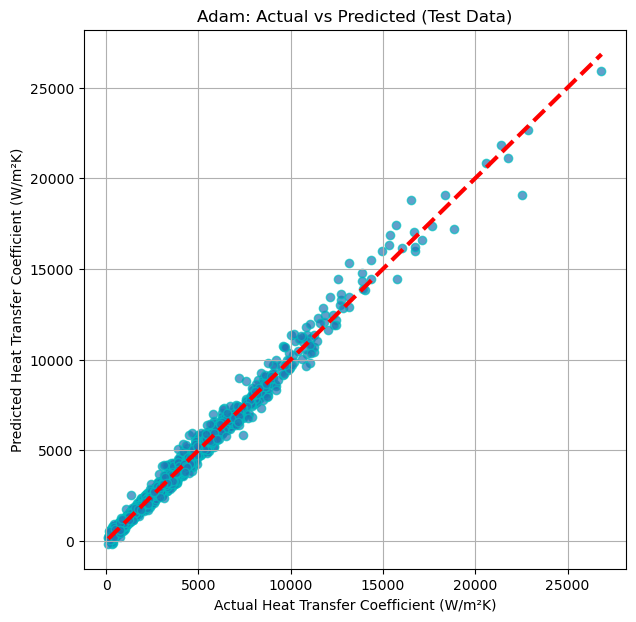

In [20]:
#Scatter Plot
mplt.figure(figsize=(7,7))
mplt.scatter(B_test,B_test_p, alpha=0.7, edgecolors='c')
mplt.plot([B_test.min(),B_test.max()], [B_test.min(),B_test.max()], 'r--', lw=3)
mplt.xlabel("Actual Heat Transfer Coefficient (W/m²K)")
mplt.ylabel("Predicted Heat Transfer Coefficient (W/m²K)")
mplt.title("Adam: Actual vs Predicted (Test Data)")
mplt.grid(True)
mplt.show()

## RMSProp

In [21]:
#Same seed as the Adam model, so the only difference between the two models is the optimizer
tf.keras.utils.set_random_seed(50)

model=Sequential([
    Input(shape=(A_train.shape[1],)),
    Dense(12,activation='relu'),
    Dense(8,activation='relu'),
    Dense(1,activation='linear')
])
#Compiling model with rmsprop
model.compile(optimizer='rmsprop', loss='mse', metrics=['mae'])

In [22]:
history_rms= model.fit(A_train,B_train_s,
                    validation_data=(A_val,B_val_s),
                    epochs=100,
                    batch_size=32,
                    verbose=0)

In [23]:
#Calculating MSE for the training data

B_train_p1=scaler_B.inverse_transform(model.predict(A_train,verbose=0))
mse_rms=mean_squared_error(B_train,B_train_p1)
print("Training MSE:",mse_rms)

Training MSE: 137563.6720557


In [24]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 12)             │           204 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 636 (2.49 KB)

 Trainable params: 317 (1.24 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 319 (1.25 KB)

In [25]:
r2_train_rms = r2_score(B_train,B_train_p1)
print("R² on training data:", r2_train_rms)

R² on training data: 0.9854401187602003


In [26]:
B_test_p1= scaler_B.inverse_transform(model.predict(A_test,verbose=0))
r2_test_rms = r2_score(B_test,B_test_p1)
mse_test_rms = mean_squared_error(B_test,B_test_p1)
print("R² on test data:", r2_test_rms)
print("Testing MSE:", mse_test_rms)

R² on test data: 0.9842582708403989
Testing MSE: 156608.40372324229


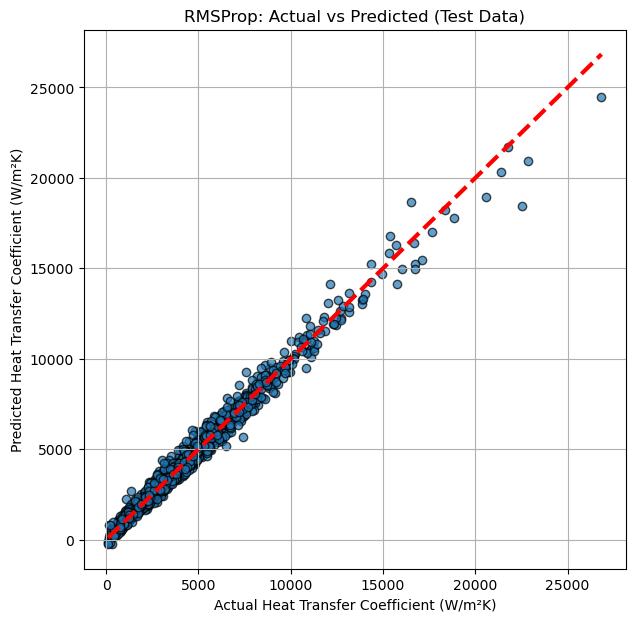

In [27]:
mplt.figure(figsize=(7,7))
mplt.scatter(B_test,B_test_p1, alpha=0.7, edgecolors='k')
mplt.plot([B_test.min(),B_test.max()], [B_test.min(),B_test.max()], 'r--', lw=3)
mplt.xlabel("Actual Heat Transfer Coefficient (W/m²K)")
mplt.ylabel("Predicted Heat Transfer Coefficient (W/m²K)")
mplt.title("RMSProp: Actual vs Predicted (Test Data)")
mplt.grid(True)
mplt.show()

## Comparisons Between Adam and RMSProp

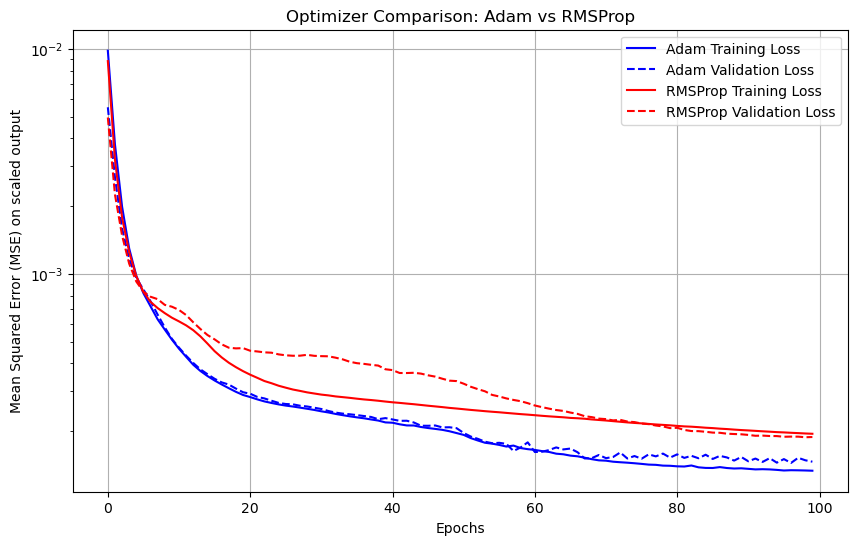

In [28]:
#The loss here is the MSE on the scaled output (0 to 1), log scale is used to see the difference clearly
mplt.figure(figsize=(10,6))
mplt.plot(history.history['loss'], label='Adam Training Loss', color='blue')
mplt.plot(history.history['val_loss'], label='Adam Validation Loss', color='blue', linestyle='--')
mplt.plot(history_rms.history['loss'], label='RMSProp Training Loss', color='red')
mplt.plot(history_rms.history['val_loss'], label='RMSProp Validation Loss', color='red', linestyle='--')
mplt.yscale('log')
mplt.xlabel('Epochs')
mplt.ylabel('Mean Squared Error (MSE) on scaled output')
mplt.title('Optimizer Comparison: Adam vs RMSProp')
mplt.legend()
mplt.grid(True)
mplt.show()

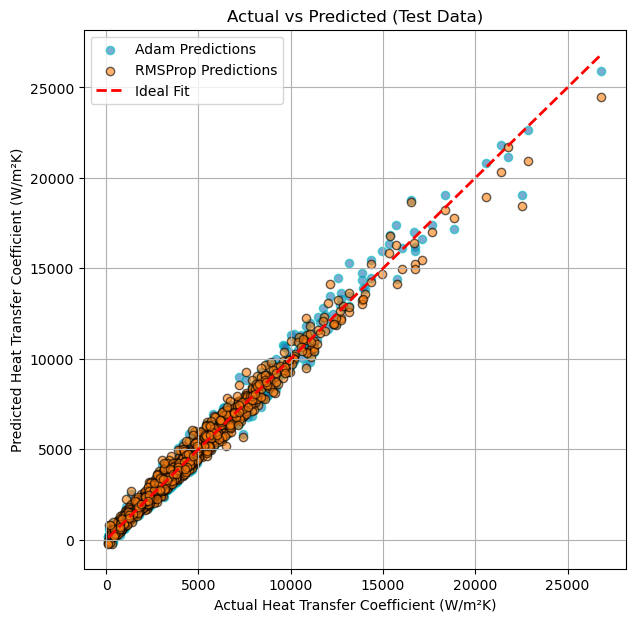

In [29]:
mplt.figure(figsize=(7,7))

mplt.scatter(B_test, B_test_p, alpha=0.6, edgecolors='c', label='Adam Predictions')
mplt.scatter(B_test, B_test_p1, alpha=0.6, edgecolors='k', label='RMSProp Predictions')

# Ideal diagonal line
mplt.plot([B_test.min(), B_test.max()],
          [B_test.min(), B_test.max()],'r--', lw=2, label='Ideal Fit')

mplt.xlabel("Actual Heat Transfer Coefficient (W/m²K)")
mplt.ylabel("Predicted Heat Transfer Coefficient (W/m²K)")
mplt.title("Actual vs Predicted (Test Data)")
mplt.legend()
mplt.grid(True)
mplt.show()

In [30]:
# Print results
print("\n •Adam Results")
print(f"Training MSE: {mse_adam:.2f}")
print(f"Testing MSE : {mse_test_adam:.2f}")
print(f"Training R² : {r2_train_adam:.4f}")
print(f"Testing R²  : {r2_test_adam:.4f}")

print("\n •RMSProp Results ")
print(f"Training MSE: {mse_rms:.2f}")
print(f"Testing MSE : {mse_test_rms:.2f}")
print(f"Training R² : {r2_train_rms:.4f}")
print(f"Testing R²  : {r2_test_rms:.4f}")


 •Adam Results
Training MSE: 103409.39
Testing MSE : 124997.75
Training R² : 0.9891
Testing R²  : 0.9874

 •RMSProp Results 
Training MSE: 137563.67
Testing MSE : 156608.40
Training R² : 0.9854
Testing R²  : 0.9843
